In [14]:
!pip -q install xgboost lightgbm joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [4]:
csv_files = sorted(glob.glob("/content/*.csv"))

print("Total CSV files found:", len(csv_files))

for i, file in enumerate(csv_files, 1):
    print(i, os.path.basename(file))

if len(csv_files) != 16:
    print("WARNING: Expected 16 files.")
    print("Check your uploaded CSV files before continuing.")

Total CSV files found: 11
1 1.benign.csv
2 1.gafgyt.combo.csv
3 1.gafgyt.junk.csv
4 1.gafgyt.scan.csv
5 1.gafgyt.tcp.csv
6 1.gafgyt.udp.csv
7 1.mirai.ack.csv
8 1.mirai.scan.csv
9 1.mirai.syn.csv
10 1.mirai.udp.csv
11 1.mirai.udpplain.csv
Check your uploaded CSV files before continuing.


In [5]:
label_mapping = {
    "benign": 0,
    "gafgyt.combo": 1,
    "gafgyt.junk": 2,
    "gafgyt.scan": 3,
    "gafgyt.tcp": 4,
    "gafgyt.udp": 5,
    "mirai.ack": 6,
    "mirai.scan": 7,
    "mirai.syn": 8,
    "mirai.udp": 9,
    "mirai.udpplain": 10
}

label_names = {
    value: key for key, value in label_mapping.items()
}

MAX_READ_PER_FILE = 10000
SAMPLE_PER_FILE = 2000
SAMPLES_PER_CLASS = 1800

all_data = []

for file in csv_files:

    filename = os.path.basename(file).lower()

    # Example: 1.gafgyt.combo.csv
    parts = filename.split(".", 1)

    if len(parts) < 2:
        print("Skipped:", filename)
        continue

    attack_type = parts[1].removesuffix(".csv")

    if attack_type not in label_mapping:
        print("Unknown class:", filename)
        continue

    # Read a small portion to save memory
    df = pd.read_csv(
        file,
        nrows=MAX_READ_PER_FILE
    )

    # Random sample from the loaded portion
    n = min(SAMPLE_PER_FILE, len(df))

    df = df.sample(
        n=n,
        random_state=RANDOM_STATE
    ).copy()

    # Assign label
    df["label"] = label_mapping[attack_type]

    all_data.append(df)

    print(filename, ":", len(df), "samples")

if not all_data:
    raise ValueError("No valid CSV files found!")

dataset = pd.concat(
    all_data,
    ignore_index=True
)

# Check all 11 classes exist
missing_classes = set(label_mapping.values()) - set(dataset["label"])

if missing_classes:
    raise ValueError(
        f"Missing classes: {missing_classes}. "
        "Check your uploaded filenames."
    )

# Determine safe balanced sample size
available_min = dataset["label"].value_counts().min()

n_per_class = min(
    SAMPLES_PER_CLASS,
    available_min
)

if n_per_class < 30:
    raise ValueError("Too few samples in at least one class.")

# Balance all classes
dataset = (
    dataset.groupby("label", group_keys=False)
    .sample(n=n_per_class, random_state=RANDOM_STATE)
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

print("\nBALANCED DATASET CREATED")
print("Total samples:", len(dataset))
print("Total classes:", dataset["label"].nunique())
print("Samples per class:", n_per_class)
print("Dataset shape:", dataset.shape)

1.benign.csv : 2000 samples
1.gafgyt.combo.csv : 2000 samples
1.gafgyt.junk.csv : 2000 samples
1.gafgyt.scan.csv : 2000 samples
1.gafgyt.tcp.csv : 2000 samples
1.gafgyt.udp.csv : 2000 samples
1.mirai.ack.csv : 2000 samples
1.mirai.scan.csv : 2000 samples
1.mirai.syn.csv : 2000 samples
1.mirai.udp.csv : 2000 samples
1.mirai.udpplain.csv : 2000 samples

BALANCED DATASET CREATED
Total samples: 19800
Total classes: 11
Samples per class: 1800
Dataset shape: (19800, 116)


In [6]:
counts = dataset["label"].value_counts().sort_index()

summary = pd.DataFrame({
    "Label": counts.index,
    "Class Name": [label_names[i] for i in counts.index],
    "Number": counts.values,
    "Percentage (%)": (
        counts.values / len(dataset) * 100
    ).round(2)
})

display(summary)

print("Total samples:", len(dataset))
print("Total percentage:", summary["Percentage (%)"].sum())

,Label,Class Name,Number,Percentage (%)
0,0,benign,1800,9.09
1,1,gafgyt.combo,1800,9.09
2,2,gafgyt.junk,1800,9.09
3,3,gafgyt.scan,1800,9.09
4,4,gafgyt.tcp,1800,9.09
5,5,gafgyt.udp,1800,9.09
6,6,mirai.ack,1800,9.09
7,7,mirai.scan,1800,9.09
8,8,mirai.syn,1800,9.09
9,9,mirai.udp,1800,9.09


Total samples: 19800
Total percentage: 99.99000000000001


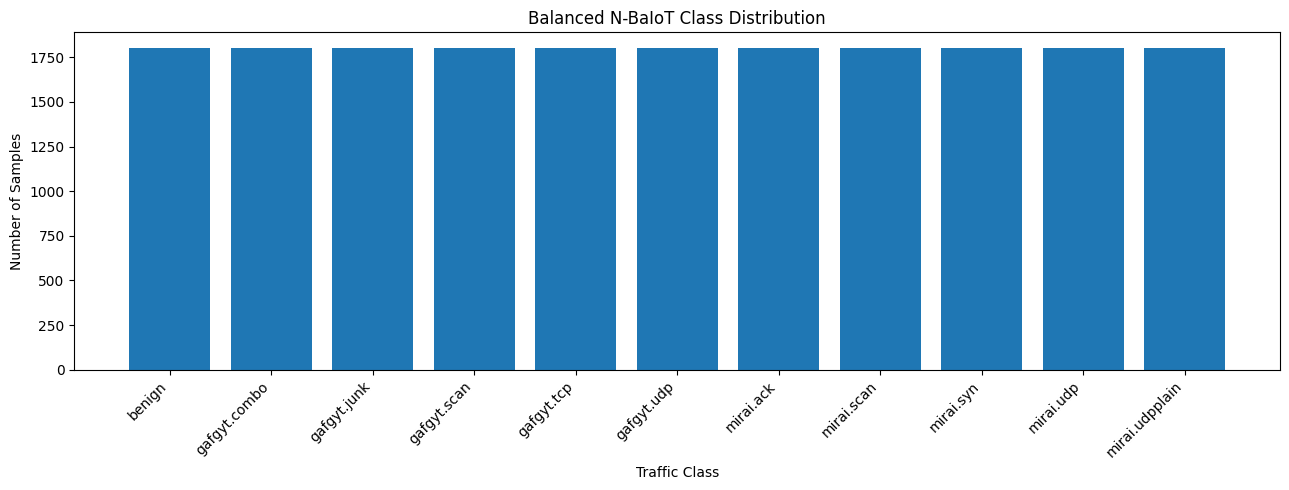

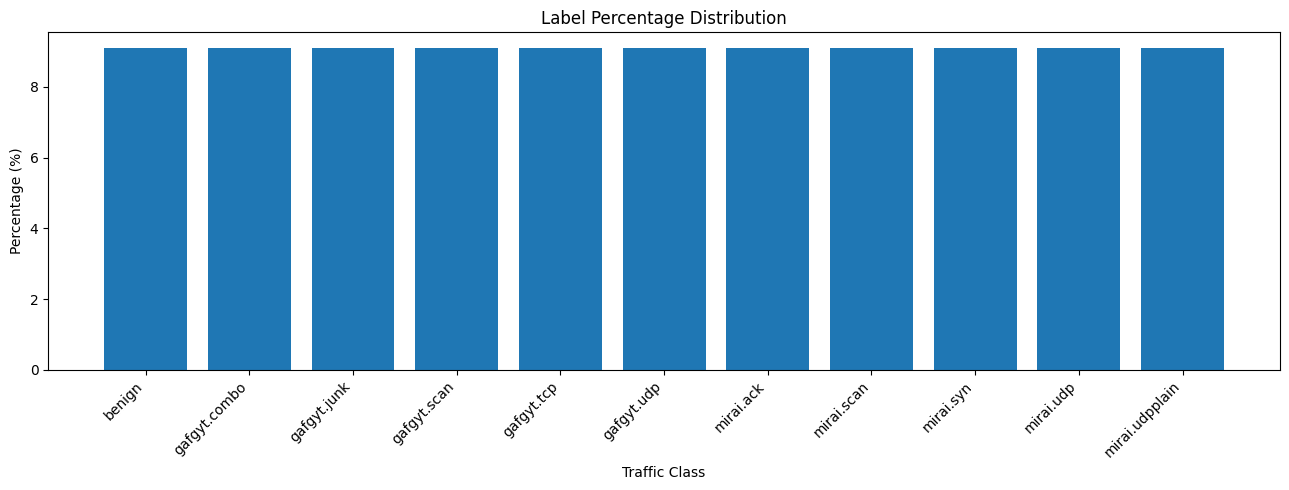

In [7]:
plt.figure(figsize=(13, 5))

plt.bar(
    summary["Class Name"],
    summary["Number"]
)

plt.title("Balanced N-BaIoT Class Distribution")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

# Percentage chart
plt.figure(figsize=(13, 5))

plt.bar(
    summary["Class Name"],
    summary["Percentage (%)"]
)

plt.title("Label Percentage Distribution")
plt.xlabel("Traffic Class")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [8]:
# Input features
X = dataset.drop(columns=["label"])

# Ensure all features are numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Replace infinity with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns containing only missing values
X = X.dropna(axis=1, how="all")

# Multiclass target: 0 to 10
y_multi = dataset["label"].astype(int)

# Binary target: 0 = benign, 1 = attack
y_binary = (y_multi != 0).astype(int)

print("Feature shape:", X.shape)
print("Binary classes:", y_binary.nunique())
print("Multiclass classes:", y_multi.nunique())
print("Missing feature values:", X.isna().sum().sum())

Feature shape: (19800, 115)
Binary classes: 2
Multiclass classes: 11
Missing feature values: 0


In [9]:
# First: 70% train, 30% temporary
X_train, X_temp, y_train_multi, y_temp_multi = train_test_split(
    X,
    y_multi,
    test_size=0.30,
    stratify=y_multi,
    random_state=RANDOM_STATE
)

# Then: 15% validation and 15% test
X_val, X_test, y_val_multi, y_test_multi = train_test_split(
    X_temp,
    y_temp_multi,
    test_size=0.50,
    stratify=y_temp_multi,
    random_state=RANDOM_STATE
)

# Binary labels from corresponding multiclass labels
y_train_binary = (y_train_multi != 0).astype(int)
y_val_binary = (y_val_multi != 0).astype(int)
y_test_binary = (y_test_multi != 0).astype(int)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 13860
Validation: 2970
Testing: 2970


Define all models

In [10]:
def create_models():

    return {

        "Logistic Regression": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(
                max_iter=100,
                random_state=42
            )
        ),

        "Decision Tree": make_pipeline(
            SimpleImputer(strategy="median"),
            DecisionTreeClassifier(
                max_depth=10,
                random_state=42
            )
        ),

        "Random Forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(
                n_estimators=60,
                max_depth=15,
                n_jobs=-1,
                random_state=42
            )
        ),

        "Extra Trees": make_pipeline(
            SimpleImputer(strategy="median"),
            ExtraTreesClassifier(
                n_estimators=60,
                max_depth=15,
                n_jobs=-1,
                random_state=42
            )
        ),

        "XGBoost": make_pipeline(
            SimpleImputer(strategy="median"),
            XGBClassifier(
                n_estimators=40,
                max_depth=5,
                learning_rate=0.1,
                tree_method="hist",
                n_jobs=-1,
                random_state=42
            )
        ),

        "LightGBM": make_pipeline(
            SimpleImputer(strategy="median"),
            LGBMClassifier(
                n_estimators=40,
                max_depth=5,
                learning_rate=0.1,
                verbosity=-1,
                n_jobs=-1,
                random_state=42
            )
        ),

        "Neural Network (MLP)": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            MLPClassifier(
                hidden_layer_sizes=(64, 32),
                max_iter=15,
                batch_size=256,
                early_stopping=False,
                random_state=42
            )
        )
    }

print("Models ready:", list(create_models().keys()))

Models ready: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'XGBoost', 'LightGBM', 'Neural Network (MLP)']


Create the training and evaluation function

In [11]:
def train_models(
    X_train, X_val,
    y_train, y_val
):

    results = []
    trained_models = {}

    for name, model in create_models().items():

        print("\nTraining:", name)

        start_time = time.time()

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        duration = time.time() - start_time

        metrics = {
            "Model": name,
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions,
                average="macro",
                zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions,
                average="macro",
                zero_division=0
            ),
            "F1 Score": f1_score(
                y_val, predictions,
                average="macro",
                zero_division=0
            ),
            "Time (seconds)": round(duration, 2)
        }

        results.append(metrics)
        trained_models[name] = model

        print("Validation accuracy:", round(metrics["Accuracy"], 4))
        print("Validation macro F1:", round(metrics["F1 Score"], 4))

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        "F1 Score",
        ascending=False
    ).reset_index(drop=True)

    return results_df, trained_models

Train binary classification models
This experiment predicts:
- 0 = Benign
- 1 = Attack

In [15]:
import warnings

binary_results, binary_models = train_models(
    X_train,
    X_val,
    y_train_binary,
    y_val_binary
)

print("\nBINARY VALIDATION RESULTS")
display(binary_results.round(4))


Training: Logistic Regression
Validation accuracy: 0.9997
Validation macro F1: 0.999

Training: Decision Tree
Validation accuracy: 0.9997
Validation macro F1: 0.999

Training: Random Forest
Validation accuracy: 0.9997
Validation macro F1: 0.999

Training: Extra Trees
Validation accuracy: 0.9997
Validation macro F1: 0.999

Training: XGBoost
Validation accuracy: 0.9997
Validation macro F1: 0.999

Training: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Validation accuracy: 0.9997
Validation macro F1: 0.999

Training: Neural Network (MLP)
Validation accuracy: 0.9993
Validation macro F1: 0.998

BINARY VALIDATION RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,Time (seconds)
0,Logistic Regression,0.9997,0.9982,0.9998,0.999,0.70
1,Decision Tree,0.9997,0.9982,0.9998,0.999,1.18
2,Random Forest,0.9997,0.9982,0.9998,0.999,1.41
3,Extra Trees,0.9997,0.9982,0.9998,0.999,0.40
4,XGBoost,0.9997,0.9982,0.9998,0.999,1.02
5,LightGBM,0.9997,0.9998,0.9981,0.999,0.73
6,Neural Network (MLP),0.9993,0.9980,0.9980,0.998,4.93


Train multiclass classification models.

This experiment classifies the 11 traffic categories.

In [16]:
multi_results, multi_models = train_models(
    X_train,
    X_val,
    y_train_multi,
    y_val_multi
)

print("\nMULTICLASS VALIDATION RESULTS")
display(multi_results.round(4))


Training: Logistic Regression
Validation accuracy: 0.8519
Validation macro F1: 0.8213

Training: Decision Tree
Validation accuracy: 0.997
Validation macro F1: 0.997

Training: Random Forest
Validation accuracy: 0.9973
Validation macro F1: 0.9973

Training: Extra Trees
Validation accuracy: 0.9976
Validation macro F1: 0.9976

Training: XGBoost
Validation accuracy: 0.9976
Validation macro F1: 0.9976

Training: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Validation accuracy: 0.998
Validation macro F1: 0.998

Training: Neural Network (MLP)
Validation accuracy: 0.8168
Validation macro F1: 0.7866

MULTICLASS VALIDATION RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,Time (seconds)
0,LightGBM,0.9980,0.9980,0.9980,0.9980,2.32
1,Extra Trees,0.9976,0.9977,0.9976,0.9976,1.05
2,XGBoost,0.9976,0.9977,0.9976,0.9976,5.12
3,Random Forest,0.9973,0.9973,0.9973,0.9973,5.97
4,Decision Tree,0.9970,0.9970,0.9970,0.9970,0.69
5,Logistic Regression,0.8519,0.8080,0.8519,0.8213,2.80
6,Neural Network (MLP),0.8168,0.7726,0.8168,0.7866,3.71


Compare model performance

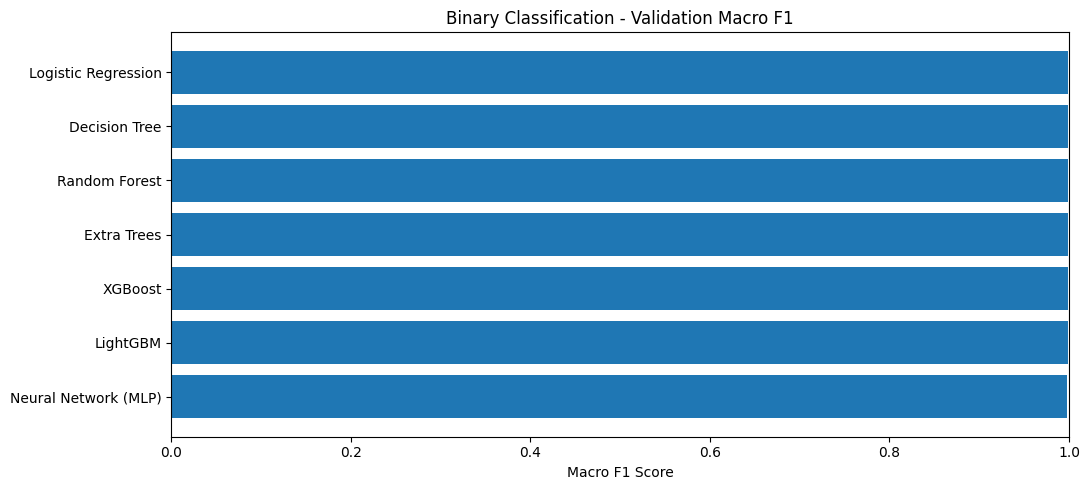

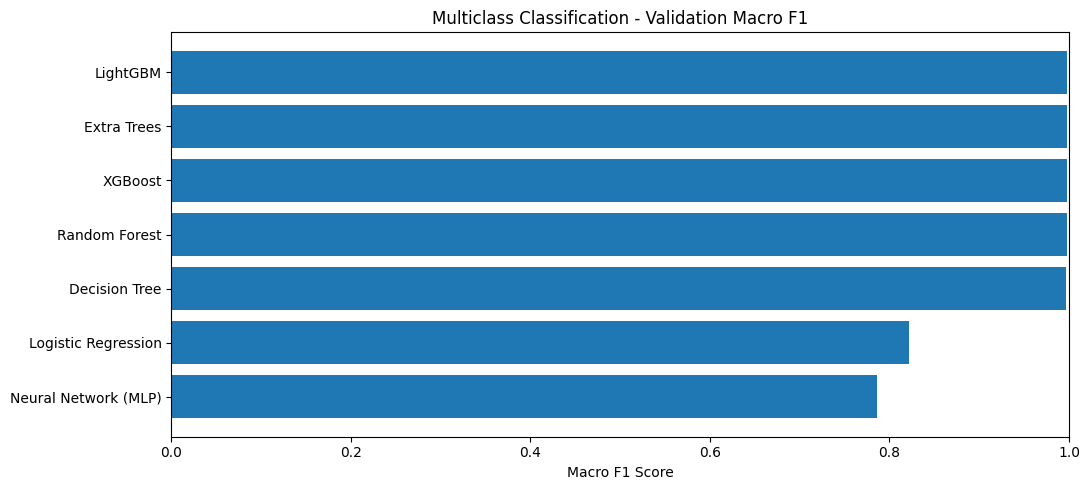

In [21]:
plt.figure(figsize=(11, 5))

plt.barh(
    binary_results["Model"],
    binary_results["F1 Score"]
)

plt.title("Binary Classification - Validation Macro F1")
plt.xlabel("Macro F1 Score")
plt.xlim(0, 1)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


plt.figure(figsize=(11, 5))

plt.barh(
    multi_results["Model"],
    multi_results["F1 Score"]
)

plt.title("Multiclass Classification - Validation Macro F1")
plt.xlabel("Macro F1 Score")
plt.xlim(0, 1)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

Evaluate best models on the untouched test set

In [22]:
# Select best models by validation score
best_binary_name = binary_results.iloc[0]["Model"]
best_multi_name = multi_results.iloc[0]["Model"]

best_binary = binary_models[best_binary_name]
best_multi = multi_models[best_multi_name]

# Predict untouched test set
binary_pred = best_binary.predict(X_test)
multi_pred = best_multi.predict(X_test)

print("BEST BINARY MODEL:", best_binary_name)
print("\nBinary Test Classification Report:")
print(
    classification_report(
        y_test_binary,
        binary_pred,
        target_names=["Benign", "Attack"],
        zero_division=0
    )
)

print("\nBEST MULTICLASS MODEL:", best_multi_name)
print("\nMulticlass Test Classification Report:")

print(
    classification_report(
        y_test_multi,
        multi_pred,
        labels=list(range(11)),
        target_names=[label_names[i] for i in range(11)],
        zero_division=0
    )
)

BEST BINARY MODEL: Logistic Regression

Binary Test Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      0.99      0.99       270
      Attack       1.00      1.00      1.00      2700

    accuracy                           1.00      2970
   macro avg       1.00      0.99      1.00      2970
weighted avg       1.00      1.00      1.00      2970


BEST MULTICLASS MODEL: LightGBM

Multiclass Test Classification Report:
                precision    recall  f1-score   support

        benign       1.00      1.00      1.00       270
  gafgyt.combo       1.00      1.00      1.00       270
   gafgyt.junk       1.00      1.00      1.00       270
   gafgyt.scan       1.00      1.00      1.00       270
    gafgyt.tcp       1.00      0.99      0.99       270
    gafgyt.udp       0.99      1.00      0.99       270
     mirai.ack       1.00      1.00      1.00       270
    mirai.scan       1.00      1.00      1.00       270
     mirai.syn      

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Plot confusion matrices

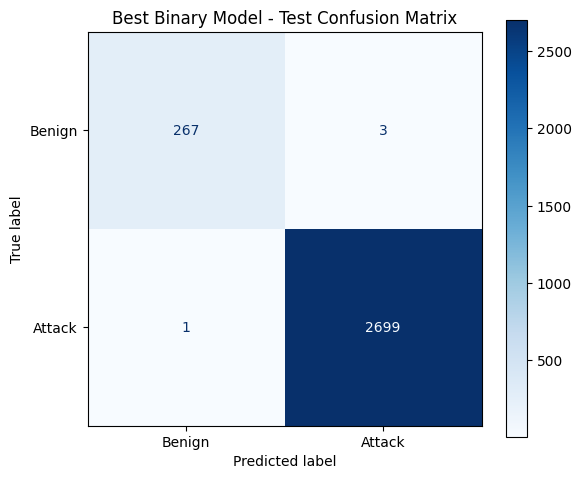

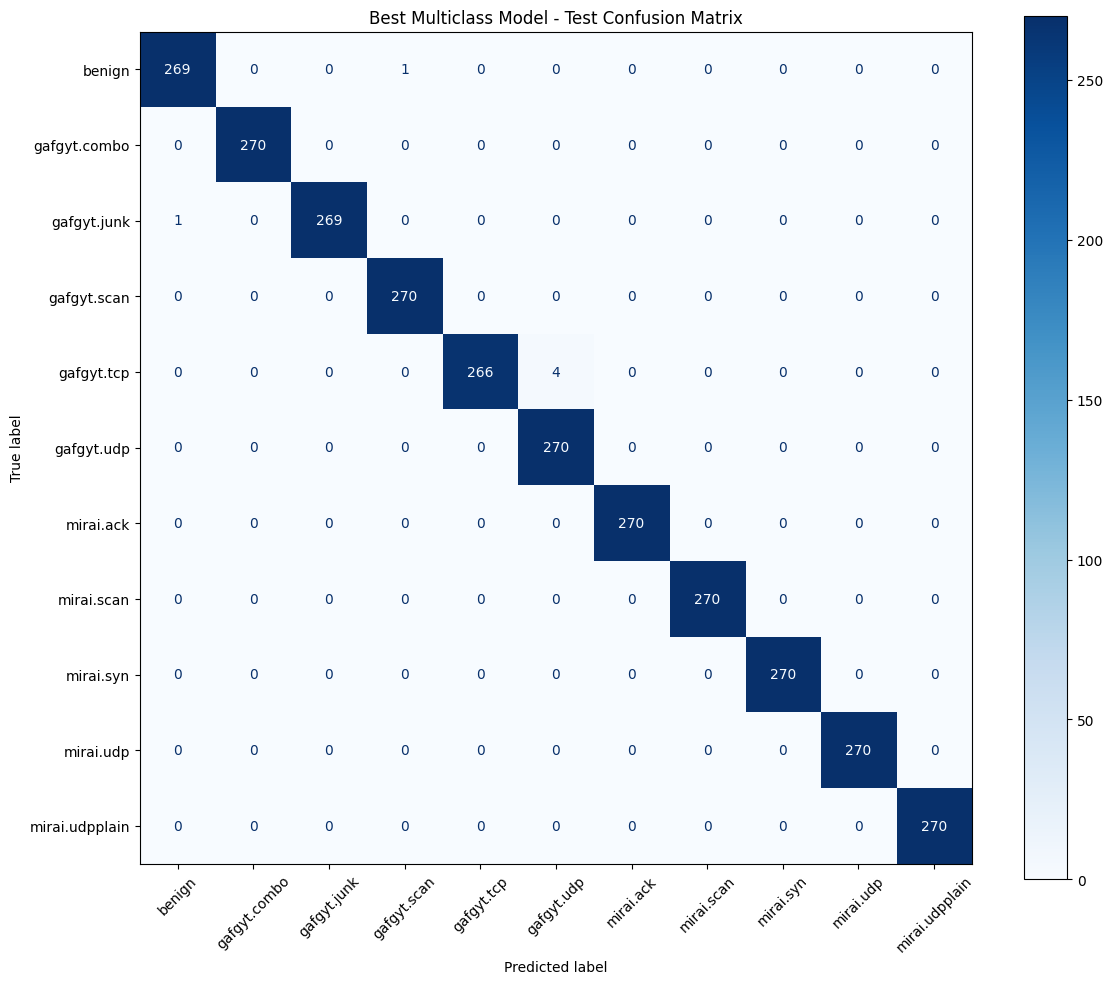

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Ensure predictions exist in the current namespace
if 'binary_pred' not in globals() or 'multi_pred' not in globals():
    best_binary_name = binary_results.iloc[0]["Model"]
    best_multi_name = multi_results.iloc[0]["Model"]

    best_binary = binary_models[best_binary_name]
    best_multi = multi_models[best_multi_name]

    binary_pred = best_binary.predict(X_test)
    multi_pred = best_multi.predict(X_test)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    binary_pred,
    display_labels=["Benign", "Attack"],
    cmap="Blues",
    ax=ax
)

plt.title("Best Binary Model - Test Confusion Matrix")
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    multi_pred,
    labels=list(range(11)),
    display_labels=[label_names[i] for i in range(11)],
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("Best Multiclass Model - Test Confusion Matrix")
plt.tight_layout()
plt.show()

Download the best model


In [24]:
import os
import joblib
import shutil
import sklearn
import numpy as np
import pandas as pd
import xgboost
import lightgbm
from google.colab import files

# Ensure best model variables are defined
if 'best_binary' not in globals() or 'best_multi' not in globals():
    best_binary_name = binary_results.iloc[0]["Model"]
    best_multi_name = multi_results.iloc[0]["Model"]
    best_binary = binary_models[best_binary_name]
    best_multi = multi_models[best_multi_name]

# 1. Compare best validation results
binary_score = binary_results.iloc[0]["F1 Score"]
multi_score = multi_results.iloc[0]["F1 Score"]

if binary_score >= multi_score:
    best_model = best_binary
    best_name = best_binary_name
    task = "binary"
    best_score = binary_score
else:
    best_model = best_multi
    best_name = best_multi_name
    task = "multiclass"
    best_score = multi_score

print("Selected Model:", best_name)
print("Task:", task)
print("Validation Macro F1:", round(best_score, 4))

# 2. Create output folder
folder = "/content/Best_NBaIoT_Model"
os.makedirs(folder, exist_ok=True)

# 3. Save trained model (including preprocessing)
joblib.dump(best_model, f"{folder}/best_model.pkl")

# 4. Save feature column names
joblib.dump(X_train.columns.tolist(), f"{folder}/feature_names.pkl")

# 5. Save label mapping
if task == "binary":
    classes = {0: "Benign", 1: "Attack"}
else:
    classes = label_names

joblib.dump(classes, f"{folder}/label_mapping.pkl")

# 6. Save required Python package versions
requirements = f"""numpy=={np.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
xgboost=={xgboost.__version__}
lightgbm=={lightgbm.__version__}
joblib=={joblib.__version__}
"""

with open(f"{folder}/requirements.txt", "w") as f:
    f.write(requirements)

# 7. Create prediction script
prediction_code = '''
import joblib
import pandas as pd

model = joblib.load("best_model.pkl")
features = joblib.load("feature_names.pkl")
labels = joblib.load("label_mapping.pkl")

def predict_csv(csv_path):
    data = pd.read_csv(csv_path)

    # Match feature names and order used in training
    X = data.reindex(columns=features)

    predictions = model.predict(X)

    data["predicted_label"] = predictions
    data["predicted_class"] = [
        labels[int(p)] for p in predictions
    ]

    return data

if __name__ == "__main__":
    result = predict_csv("new_data.csv")
    print(result[["predicted_label", "predicted_class"]].head())
'''

with open(f"{folder}/predict.py", "w") as f:
    f.write(prediction_code)

# 8. Create ZIP
zip_path = shutil.make_archive(
    "/content/Best_NBaIoT_Model",
    "zip",
    folder
)

# 9. Download
files.download(zip_path)

print("Best model package downloaded successfully!")

Selected Model: Logistic Regression
Task: binary
Validation Macro F1: 0.999


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Best model package downloaded successfully!


New test train

In [26]:
import os
import glob
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# 1. Load all samples from all uploaded CSV files
all_dfs = []

for file in csv_files:
    filename = os.path.basename(file).lower()
    parts = filename.split(".", 1)

    if len(parts) < 2:
        continue

    attack_type = parts[1].removesuffix(".csv")

    # Read full CSV without limits
    df_temp = pd.read_csv(file)

    # Assign binary label: 0 for benign, 1 for attack
    df_temp["label"] = 0 if attack_type == "benign" else 1

    all_dfs.append(df_temp)
    print(f"{filename}: loaded {len(df_temp)} samples")

# Combine everything
full_dataset = pd.concat(all_dfs, ignore_index=True)

# 2. Extract features and target labels
X_full = full_dataset.drop(columns=["label"])
X_full = X_full.apply(pd.to_numeric, errors="coerce")
X_full = X_full.replace([np.inf, -np.inf], np.nan)
X_full = X_full.dropna(axis=1, how="all")

y_full = full_dataset["label"].astype(int)

print(f"\nFull dataset loaded successfully!")
print(f"Total features: {X_full.shape[1]}")
print(f"Total samples: {len(full_dataset)}")
print(f"Class counts:\n{y_full.value_counts(normalize=True).round(4) * 100}")

1.benign.csv: loaded 49548 samples
1.gafgyt.combo.csv: loaded 59718 samples
1.gafgyt.junk.csv: loaded 29068 samples
1.gafgyt.scan.csv: loaded 29849 samples
1.gafgyt.tcp.csv: loaded 92141 samples
1.gafgyt.udp.csv: loaded 105874 samples
1.mirai.ack.csv: loaded 102195 samples
1.mirai.scan.csv: loaded 107685 samples
1.mirai.syn.csv: loaded 122573 samples
1.mirai.udp.csv: loaded 237665 samples
1.mirai.udpplain.csv: loaded 81982 samples

Full dataset loaded successfully!
Total features: 115
Total samples: 1018298
Class counts:
label
1    95.13
0     4.87
Name: proportion, dtype: float64


In [27]:
# 3. Split into 80% train and 20% test using a stratified split
X_tr, X_te, y_tr, y_te = train_test_split(
    X_full,
    y_full,
    test_size=0.20,
    stratify=y_full,
    random_state=RANDOM_STATE
)

print(f"Training set: {len(X_tr)} samples")
print(f"Test set: {len(X_te)} samples")

# 4. Train our best model (Logistic Regression) on the entire 80% training set
print(f"\nTraining {best_binary_name} on 80% train set...")
best_binary.fit(X_tr, y_tr)

# 5. Evaluate on the untouched 20% test set
y_pred = best_binary.predict(X_te)
accuracy = accuracy_score(y_te, y_pred)

print(f"\nFinal Test Accuracy: {accuracy:.6f}")
print("\nFinal Test Classification Report:")
print(
    classification_report(
        y_te,
        y_pred,
        target_names=["Benign", "Attack"],
        zero_division=0
    )
)

Training set: 814638 samples
Test set: 203660 samples

Training Logistic Regression on 80% train set...

Final Test Accuracy: 0.999764

Final Test Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      9910
      Attack       1.00      1.00      1.00    193750

    accuracy                           1.00    203660
   macro avg       1.00      1.00      1.00    203660
weighted avg       1.00      1.00      1.00    203660



### Multiclass Logistic Regression Evaluation
Let's evaluate the multiclass Logistic Regression model on the dataset.

In [28]:
# Retrieve the multiclass Logistic Regression pipeline
mc_lr_model = multi_models['Logistic Regression']

# Fit on the training set
print("Training Multiclass Logistic Regression...")
mc_lr_model.fit(X_train, y_train_multi)

# Predict on the untouched test set
mc_lr_pred = mc_lr_model.predict(X_test)

# Print classification report
print("\nMulticlass Logistic Regression Test Classification Report:")
print(
    classification_report(
        y_test_multi,
        mc_lr_pred,
        labels=list(range(11)),
        target_names=[label_names[i] for i in range(11)],
        zero_division=0
    )
)

Training Multiclass Logistic Regression...

Multiclass Logistic Regression Test Classification Report:
                precision    recall  f1-score   support

        benign       1.00      0.99      0.99       270
  gafgyt.combo       0.66      0.79      0.72       270
   gafgyt.junk       0.73      0.59      0.65       270
   gafgyt.scan       0.99      0.99      0.99       270
    gafgyt.tcp       0.50      0.00      0.01       270
    gafgyt.udp       0.50      1.00      0.67       270
     mirai.ack       1.00      0.98      0.99       270
    mirai.scan       1.00      1.00      1.00       270
     mirai.syn       1.00      1.00      1.00       270
     mirai.udp       0.98      1.00      0.99       270
mirai.udpplain       1.00      1.00      1.00       270

      accuracy                           0.85      2970
     macro avg       0.85      0.85      0.82      2970
  weighted avg       0.85      0.85      0.82      2970



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Improving Struggling Classes with Class-Weight Balancing
We will retrain the multiclass Logistic Regression model by configuring it with balanced class weights to address the severe performance drops in specific classes like `gafgyt.tcp`.

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report

# Create a multiclass Logistic Regression pipeline with balanced class weights
improved_mc_lr = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        max_iter=500,
        class_weight='balanced',
        random_state=RANDOM_STATE
    )
)

print("Training improved Multiclass Logistic Regression with class-weight balancing...")
improved_mc_lr.fit(X_train, y_train_multi)

# Predict on the untouched test set
improved_pred = improved_mc_lr.predict(X_test)

# Display the improved results
print("\nImproved Multiclass Logistic Regression Test Classification Report:")
print(
    classification_report(
        y_test_multi,
        improved_pred,
        labels=list(range(11)),
        target_names=[label_names[i] for i in range(11)],
        zero_division=0
    )
)

Training improved Multiclass Logistic Regression with class-weight balancing...

Improved Multiclass Logistic Regression Test Classification Report:
                precision    recall  f1-score   support

        benign       0.99      0.99      0.99       270
  gafgyt.combo       0.69      0.74      0.71       270
   gafgyt.junk       0.72      0.67      0.70       270
   gafgyt.scan       1.00      0.99      0.99       270
    gafgyt.tcp       0.50      1.00      0.66       270
    gafgyt.udp       0.00      0.00      0.00       270
     mirai.ack       1.00      1.00      1.00       270
    mirai.scan       1.00      1.00      1.00       270
     mirai.syn       1.00      1.00      1.00       270
     mirai.udp       0.99      1.00      0.99       270
mirai.udpplain       1.00      1.00      1.00       270

      accuracy                           0.85      2970
     macro avg       0.81      0.85      0.82      2970
  weighted avg       0.81      0.85      0.82      2970



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Comparison of Final Trained Models
Let's gather the accuracies of the three models we trained and evaluated on their respective test sets for a clear comparison.

,Model Run,Accuracy (%)
0,Binary Logistic Regression (Full Dataset),99.9764
1,Baseline Multiclass Logistic Regression,84.8148
2,Balanced Multiclass Logistic Regression,85.2862


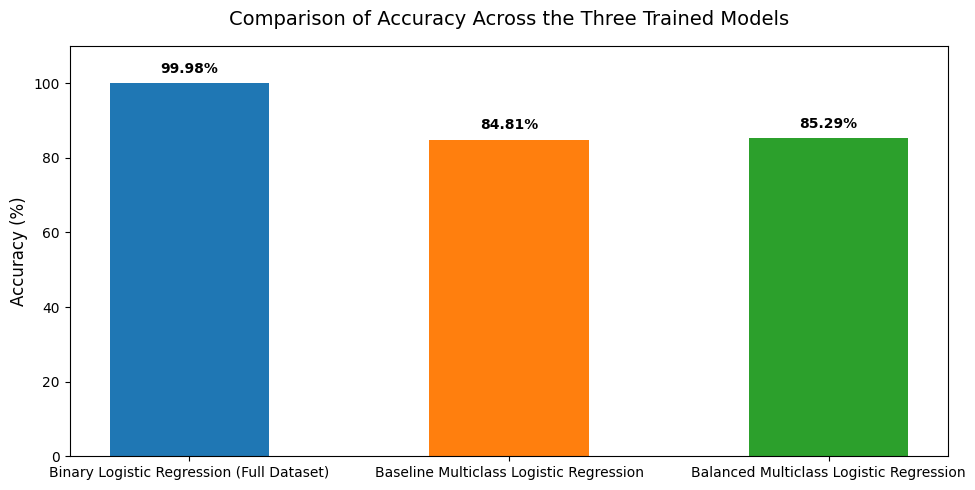

In [30]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score

# Calculate accuracies
binary_acc = accuracy_score(y_te, y_pred) # Full dataset binary model
baseline_multi_acc = accuracy_score(y_test_multi, mc_lr_pred) # Baseline multiclass model
improved_multi_acc = accuracy_score(y_test_multi, improved_pred) # Balanced class-weight multiclass model

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    "Model Run": [
        "Binary Logistic Regression (Full Dataset)",
        "Baseline Multiclass Logistic Regression",
        "Balanced Multiclass Logistic Regression"
    ],
    "Accuracy (%)": [
        binary_acc * 100,
        baseline_multi_acc * 100,
        improved_multi_acc * 100
    ]
})

display(comparison_df.round(4))

# Plot the accuracies for visualization
plt.figure(figsize=(10, 5))
bars = plt.bar(
    comparison_df["Model Run"],
    comparison_df["Accuracy (%)"],
    color=["#1f77b4", "#ff7f0e", "#2ca02c"],
    width=0.5
)

plt.title("Comparison of Accuracy Across the Three Trained Models", fontsize=14, pad=15)
plt.ylabel("Accuracy (%)", fontsize=12)
plt.ylim(0, 110)

# Add values on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2.0,
        yval + 2,
        f"{yval:.2f}%",
        ha='center',
        va='bottom',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

### Download Balanced Multiclass Logistic Regression Package
We will save and download the improved multiclass Logistic Regression pipeline, along with requirements and a deployment script.

In [31]:
import os
import joblib
import shutil
import sklearn
import numpy as np
import pandas as pd
import xgboost
import lightgbm
from google.colab import files

# 1. Define output folder for multiclass model
mc_folder = "/content/Balanced_Multiclass_NBaIoT_Model"
os.makedirs(mc_folder, exist_ok=True)

# 2. Save the trained balanced multiclass model pipeline
joblib.dump(improved_mc_lr, f"{mc_folder}/best_model.pkl")

# 3. Save feature column names
joblib.dump(X_train.columns.tolist(), f"{mc_folder}/feature_names.pkl")

# 4. Save the multiclass label mapping
joblib.dump(label_names, f"{mc_folder}/label_mapping.pkl")

# 5. Save required Python package versions
mc_requirements = f"""numpy=={np.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
xgboost=={xgboost.__version__}
lightgbm=={lightgbm.__version__}
joblib=={joblib.__version__}
"""

with open(f"{mc_folder}/requirements.txt", "w") as f:
    f.write(mc_requirements)

# 6. Create prediction script
mc_prediction_code = '''
import joblib
import pandas as pd

model = joblib.load("best_model.pkl")
features = joblib.load("feature_names.pkl")
labels = joblib.load("label_mapping.pkl")

def predict_csv(csv_path):
    data = pd.read_csv(csv_path)

    # Match feature names and order used in training
    X = data.reindex(columns=features)

    predictions = model.predict(X)

    data["predicted_label"] = predictions
    data["predicted_class"] = [
        labels[int(p)] for p in predictions
    ]

    return data

if __name__ == "__main__":
    result = predict_csv("new_data.csv")
    print(result[["predicted_label", "predicted_class"]].head())
'''

with open(f"{mc_folder}/predict.py", "w") as f:
    f.write(mc_prediction_code)

# 7. Create ZIP archive
mc_zip_path = shutil.make_archive(
    "/content/Balanced_Multiclass_NBaIoT_Model",
    "zip",
    mc_folder
)

# 8. Trigger browser download
files.download(mc_zip_path)
print("Balanced Multiclass Logistic Regression package prepared and download triggered!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Balanced Multiclass Logistic Regression package prepared and download triggered!


### Training Multiclass Logistic Regression on the Full Dataset
We will prepare the full dataset labels for multiclass classification, split it into 80% train and 20% test subsets, and then train both the **Baseline Multiclass Logistic Regression** and the **Balanced Multiclass Logistic Regression** on the full training set (~814,638 samples).

In [32]:
import os
import glob
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# 1. Load all samples from all uploaded CSV files and preserve multi-class labels
all_multi_dfs = []

for file in csv_files:
    filename = os.path.basename(file).lower()
    parts = filename.split(".", 1)

    if len(parts) < 2:
        continue

    attack_type = parts[1].removesuffix(".csv")

    if attack_type not in label_mapping:
        continue

    # Read full CSV without limits
    df_temp = pd.read_csv(file)

    # Assign full multiclass label
    df_temp["label"] = label_mapping[attack_type]

    all_multi_dfs.append(df_temp)

# Combine everything into a single dataframe
full_multi_dataset = pd.concat(all_multi_dfs, ignore_index=True)

# 2. Extract features and target labels
X_full_multi = full_multi_dataset.drop(columns=["label"])
X_full_multi = X_full_multi.apply(pd.to_numeric, errors="coerce")
X_full_multi = X_full_multi.replace([np.inf, -np.inf], np.nan)
X_full_multi = X_full_multi.dropna(axis=1, how="all")

y_full_multi = full_multi_dataset["label"].astype(int)

print(f"Full Multiclass Dataset Loaded!")
print(f"Total features: {X_full_multi.shape[1]}")
print(f"Total samples: {len(full_multi_dataset)}")


Full Multiclass Dataset Loaded!
Total features: 115
Total samples: 1018298


In [33]:
# 3. Split full multiclass dataset into 80% train and 20% test sets using a stratified split
X_tr_multi, X_te_multi, y_tr_multi, y_te_multi = train_test_split(
    X_full_multi,
    y_full_multi,
    test_size=0.20,
    stratify=y_full_multi,
    random_state=RANDOM_STATE
)

print(f"Multiclass Training set: {len(X_tr_multi)} samples")
print(f"Multiclass Test set: {len(X_te_multi)} samples")

Multiclass Training set: 814638 samples
Multiclass Test set: 203660 samples


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
import warnings

# 4. Train Baseline Multiclass Logistic Regression on full dataset
baseline_mc_lr_full = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        max_iter=500,
        random_state=RANDOM_STATE
    )
)

print("Training Baseline Multiclass Logistic Regression on 80% full train set...")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    baseline_mc_lr_full.fit(X_tr_multi, y_tr_multi)

# Evaluate baseline on untouched test set
baseline_pred_full = baseline_mc_lr_full.predict(X_te_multi)
baseline_acc_full = accuracy_score(y_te_multi, baseline_pred_full)

print(f"\nBaseline Multiclass Test Accuracy: {baseline_acc_full:.6f}")
print("\nBaseline Multiclass Test Classification Report:")
print(
    classification_report(
        y_te_multi,
        baseline_pred_full,
        labels=list(range(11)),
        target_names=[label_names[i] for i in range(11)],
        zero_division=0
    )
)

Training Baseline Multiclass Logistic Regression on 80% full train set...

Baseline Multiclass Test Accuracy: 0.891550

Baseline Multiclass Test Classification Report:
                precision    recall  f1-score   support

        benign       1.00      1.00      1.00      9910
  gafgyt.combo       0.84      0.87      0.85     11944
   gafgyt.junk       0.71      0.66      0.68      5813
   gafgyt.scan       1.00      1.00      1.00      5970
    gafgyt.tcp       0.28      0.00      0.00     18428
    gafgyt.udp       0.53      1.00      0.70     21175
     mirai.ack       1.00      1.00      1.00     20439
    mirai.scan       1.00      1.00      1.00     21537
     mirai.syn       1.00      1.00      1.00     24515
     mirai.udp       1.00      1.00      1.00     47533
mirai.udpplain       1.00      1.00      1.00     16396

      accuracy                           0.89    203660
     macro avg       0.85      0.87      0.84    203660
  weighted avg       0.87      0.89      0.86 

In [6]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split

# Define parameters locally
RANDOM_STATE = 42

# Ensure label mapping and names are defined
label_mapping = {
    "benign": 0,
    "gafgyt.combo": 1,
    "gafgyt.junk": 2,
    "gafgyt.scan": 3,
    "gafgyt.tcp": 4,
    "gafgyt.udp": 5,
    "mirai.ack": 6,
    "mirai.scan": 7,
    "mirai.syn": 8,
    "mirai.udp": 9,
    "mirai.udpplain": 10
}
label_names = {value: key for key, value in label_mapping.items()}

# If variables do not exist in the active namespace, reconstruct them safely
if 'X_tr_multi' not in globals() or 'y_tr_multi' not in globals():
    print("Re-loading full multiclass dataset and splitting variables...")
    csv_files = sorted(glob.glob("/content/*.csv"))
    all_multi_dfs = []

    for file in csv_files:
        filename = os.path.basename(file).lower()
        parts = filename.split(".", 1)
        if len(parts) < 2:
            continue
        attack_type = parts[1].removesuffix(".csv")
        if attack_type not in label_mapping:
            continue

        df_temp = pd.read_csv(file)
        df_temp["label"] = label_mapping[attack_type]
        all_multi_dfs.append(df_temp)

    full_multi_dataset = pd.concat(all_multi_dfs, ignore_index=True)
    X_full_multi = full_multi_dataset.drop(columns=["label"])
    X_full_multi = X_full_multi.apply(pd.to_numeric, errors="coerce")
    X_full_multi = X_full_multi.replace([np.inf, -np.inf], np.nan)
    X_full_multi = X_full_multi.dropna(axis=1, how="all")
    y_full_multi = full_multi_dataset["label"].astype(int)

    X_tr_multi, X_te_multi, y_tr_multi, y_te_multi = train_test_split(
        X_full_multi,
        y_full_multi,
        test_size=0.20,
        stratify=y_full_multi,
        random_state=RANDOM_STATE
    )

# 5. Train Balanced Multiclass Logistic Regression on full dataset
balanced_mc_lr_full = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        max_iter=500,
        class_weight='balanced',
        random_state=RANDOM_STATE
    )
)

print("Training Balanced Multiclass Logistic Regression on 80% full train set...")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    balanced_mc_lr_full.fit(X_tr_multi, y_tr_multi)

# Evaluate balanced model on untouched test set
balanced_pred_full = balanced_mc_lr_full.predict(X_te_multi)
balanced_acc_full = accuracy_score(y_te_multi, balanced_pred_full)

print(f"\nBalanced Multiclass Test Accuracy: {balanced_acc_full:.6f}")
print("\nBalanced Multiclass Test Classification Report:")
print(
    classification_report(
        y_te_multi,
        balanced_pred_full,
        labels=list(range(11)),
        target_names=[label_names[i] for i in range(11)],
        zero_division=0
    )
)

Re-loading full multiclass dataset and splitting variables...
Training Balanced Multiclass Logistic Regression on 80% full train set...

Balanced Multiclass Test Accuracy: 0.867303

Balanced Multiclass Test Classification Report:
                precision    recall  f1-score   support

        benign       1.00      1.00      1.00      9910
  gafgyt.combo       0.95      0.55      0.70     11944
   gafgyt.junk       0.50      0.94      0.66      5813
   gafgyt.scan       1.00      1.00      1.00      5970
    gafgyt.tcp       0.47      1.00      0.63     18428
    gafgyt.udp       0.57      0.00      0.00     21175
     mirai.ack       1.00      1.00      1.00     20439
    mirai.scan       1.00      1.00      1.00     21537
     mirai.syn       1.00      1.00      1.00     24515
     mirai.udp       1.00      1.00      1.00     47533
mirai.udpplain       1.00      1.00      1.00     16396

      accuracy                           0.87    203660
     macro avg       0.86      0.86     

In [3]:
import os
import glob
import joblib
import shutil
import sklearn
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from google.colab import files

RANDOM_STATE = 42

# Define label mapping locally
label_mapping = {
    "benign": 0,
    "gafgyt.combo": 1,
    "gafgyt.junk": 2,
    "gafgyt.scan": 3,
    "gafgyt.tcp": 4,
    "gafgyt.udp": 5,
    "mirai.ack": 6,
    "mirai.scan": 7,
    "mirai.syn": 8,
    "mirai.udp": 9,
    "mirai.udpplain": 10
}
label_names = {value: key for key, value in label_mapping.items()}

# Ensure multiclass training splits exist in active memory
if 'X_tr_multi' not in globals() or 'y_tr_multi' not in globals():
    print("Re-building full multiclass dataset splits from uploaded files...")
    csv_files = sorted(glob.glob("/content/*.csv"))
    all_multi_dfs = []

    for file in csv_files:
        filename = os.path.basename(file).lower()
        parts = filename.split(".", 1)
        if len(parts) < 2:
            continue
        attack_type = parts[1].removesuffix(".csv")
        if attack_type not in label_mapping:
            continue

        df_temp = pd.read_csv(file)
        df_temp["label"] = label_mapping[attack_type]
        all_multi_dfs.append(df_temp)

    full_multi_dataset = pd.concat(all_multi_dfs, ignore_index=True)
    X_full_multi = full_multi_dataset.drop(columns=["label"])
    X_full_multi = X_full_multi.apply(pd.to_numeric, errors="coerce")
    X_full_multi = X_full_multi.replace([np.inf, -np.inf], np.nan)
    X_full_multi = X_full_multi.dropna(axis=1, how="all")
    y_full_multi = full_multi_dataset["label"].astype(int)

    X_tr_multi, X_te_multi, y_tr_multi, y_te_multi = train_test_split(
        X_full_multi,
        y_full_multi,
        test_size=0.20,
        stratify=y_full_multi,
        random_state=RANDOM_STATE
    )

# 1. Define and train the Baseline Multiclass Random Forest model on the full dataset
print("Initializing Random Forest pipeline...")
rf_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=60,
        max_depth=15,
        n_jobs=-1,
        random_state=42
    )
)

print("Fitting Baseline Multiclass Random Forest on 80% full dataset training set (~814,638 samples)... This might take a moment...")
rf_pipeline.fit(X_tr_multi, y_tr_multi)
print("Random Forest model training completed successfully!")

# 2. Define output folder for the package
rf_folder = "/content/Baseline_Multiclass_RF_Model"
os.makedirs(rf_folder, exist_ok=True)

# 3. Save the trained pipeline
joblib.dump(rf_pipeline, f"{rf_folder}/best_model.pkl")

# 4. Save feature column names
joblib.dump(X_tr_multi.columns.tolist(), f"{rf_folder}/feature_names.pkl")

# 5. Save the multiclass label mapping
joblib.dump(label_names, f"{rf_folder}/label_mapping.pkl")

# 6. Save package requirements
requirements_content = f"""numpy=={np.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
joblib=={joblib.__version__}
"""
with open(f"{rf_folder}/requirements.txt", "w") as f:
    f.write(requirements_content)

# 7. Create a clean prediction script template
predict_script = '''
import joblib
import pandas as pd

model = joblib.load("best_model.pkl")
features = joblib.load("feature_names.pkl")
labels = joblib.load("label_mapping.pkl")

def predict_csv(csv_path):
    data = pd.read_csv(csv_path)

    # Align columns to what the model expects
    X = data.reindex(columns=features)

    predictions = model.predict(X)

    data["predicted_label"] = predictions
    data["predicted_class"] = [labels[int(p)] for p in predictions]

    return data

if __name__ == "__main__":
    # Usage: replace "new_data.csv" with your threat evaluation target file
    try:
        result = predict_csv("new_data.csv")
        print(result[["predicted_label", "predicted_class"]].head())
    except FileNotFoundError:
        print("To test, place a \'new_data.csv\' in this folder or call predict_csv with a valid path.")
'''
with open(f"{rf_folder}/predict.py", "w") as f:
    f.write(predict_script)

# 8. Create ZIP archive and trigger the download
rf_zip_path = shutil.make_archive(
    "/content/Baseline_Multiclass_RF_Model",
    "zip",
    rf_folder
)

print("Triggering browser download of the model package...")
files.download(rf_zip_path)

Re-building full multiclass dataset splits from uploaded files...
Initializing Random Forest pipeline...
Fitting Baseline Multiclass Random Forest on 80% full dataset training set (~814,638 samples)... This might take a moment...
Random Forest model training completed successfully!
Triggering browser download of the model package...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>